# 📓 NB-04 — Atividade Avaliativa: Agente de Patrulha Autônomo
## ESP004 — Sistemas Autônomos Robóticos | PPGESP/IFBA 2026.2
**Autores:** Prof. Dr. José Alberto Díaz Amado · Prof. Dr. João Erivando Soares Marques

---
## 📋 Instruções

Este notebook é o **template oficial** da atividade avaliativa.
Complete as células marcadas com `# TODO` e entregue o notebook commitado no GitHub.

### Rubrica (100 pontos)
| Etapa | Pontos |
|-------|--------|
| Repositório GitHub correto (estrutura, .gitignore, ≥5 commits) | 10 |
| Máquina de estados com 4 estados implementados | 20 |
| Robô percorre quadrado 2m×4 no Gazebo sem travar | 15 |
| Parada segura ao detectar obstáculo + retomada | 15 |
| Bag commitado com ≥500 amostras de /odom | 10 |
| Notebook com trajetória + métricas commitado | 15 |
| Modelo treinado no Colab (≥80% acc) commitado | 10 |
| Nó com PyTorch operacional no ROS 2 | 5 |

---
## 📦 Identificação do Aluno

In [1]:
# ═══════════════════════════════════════════════════════════
# IDENTIFICAÇÃO — Preencha seus dados
# ═══════════════════════════════════════════════════════════

ALUNO_NOME   = "Carlos Alberto de Araujo Pereira Filho"
ALUNO_EMAIL  = "carlospereira@ifba.edu.br | carlospereira.179@gmail.com"
GITHUB_USER  = "carlospereira179"
REPO_URL     = "https://github.com/carlospereira179/PPGESP-ESPA04-34"
DATA_ENTREGA = "2026-11-13"

print('=' * 55)
print('  ATIVIDADE AVALIATIVA — ESP004')
print('  Agente de Patrulha Autônomo')
print('=' * 55)
print(f'Aluno:    {ALUNO_NOME}')
print(f'Email:    {ALUNO_EMAIL}')
print(f'GitHub:   {GITHUB_USER}')
print(f'Repo:     {REPO_URL}')
print(f'Entrega:  {DATA_ENTREGA}')

  ATIVIDADE AVALIATIVA — ESP004
  Agente de Patrulha Autônomo
Aluno:    Carlos Alberto de Araujo Pereira Filho
Email:    carlospereira@ifba.edu.br | carlospereira.179@gmail.com
GitHub:   carlospereira179
Repo:     https://github.com/carlospereira179/PPGESP-ESPA04-34
Entrega:  2026-11-13


---
## Etapa 1 — Verificar Repositório GitHub (10 pts)

In [2]:
# ═══════════════════════════════════════════════════════════
# ETAPA 1 — Verificar repositório e estrutura
# ═══════════════════════════════════════════════════════════
import subprocess, os

# Verificar se estamos dentro de um repositório git
r = subprocess.run(['git', 'rev-parse', '--show-toplevel'],
                   capture_output=True, text=True)
if r.returncode == 0:
    repo_root = r.stdout.strip()
    print(f'✅ Repositório git encontrado: {repo_root}')
else:
    print('🔴 NÃO está dentro de um repositório git!')
    print('   Execute: git init && git remote add origin <URL>')

# Verificar commits
r2 = subprocess.run(['git', 'log', '--oneline'],
                    capture_output=True, text=True)
commits = [l for l in r2.stdout.strip().split('\n') if l]
n_commits = len(commits)
print(f'\nCommits: {n_commits}')
for c in commits[:8]:
    print(f'  {c}')

if n_commits >= 5:
    print(f'\n🟢 {n_commits} commits — Requisito cumprido (≥5)')
else:
    print(f'\n🔴 Apenas {n_commits} commits. Faça mais commits conforme avança.')

# Verificar .gitignore
gi = os.path.join(repo_root if r.returncode==0 else '.', '.gitignore')
if os.path.exists(gi):
    print('🟢 .gitignore encontrado')
else:
    print('🔴 .gitignore não encontrado — crie-o!')

✅ Repositório git encontrado: /home/carlos/ppgesp_ws/PPGESP-ESPA04-34

Commits: 5
  aed3d0b Add new obstacle and increased total time of execution to 60s
  062376e Add cell to simulate odometry
  6255cd3 add .gitignore
  dbd63f2 Identificação do aluno
  1952c95 initial commit

🟢 5 commits — Requisito cumprido (≥5)
🟢 .gitignore encontrado


---
## Etapa 2 — Máquina de Estados do Agente de Patrulha (20 pts)

In [6]:
# ═══════════════════════════════════════════════════════════
# ETAPA 2 — Simulando a odometria com base nos comandos
# ═══════════════════════════════════════════════════════════
import rclpy
from rclpy.node import Node
from geometry_msgs.msg import Twist
from nav_msgs.msg import Odometry
import math, time

class OdomSimulationNode(Node):
    def __init__(self):
        super().__init__('odom_simulation')
        
        self.sub_cmd = self.create_subscription(Twist, '/cmd_vel', self._cmd_callback, 10) # Subscriber do tópico /cmd_vel
        self.pub_odom = self.create_publisher(Odometry, '/odom', 10) # Publisher do tópico /odom
        
        # Estado estimado do robô
        self.x = 0.0
        self.y = 0.0
        self.theta = 0.0
        self.v = 0.0
        self.omega = 0.0
        
        self.last_time = time.time()
        self.timer = self.create_timer(0.05, self._update_odometry) # 20 Hz

    def _cmd_callback(self, msg: Twist): # Callback do subscriber, executado quando o tópico recebe uma nova mensagem
        self.v = msg.linear.x
        self.omega = msg.angular.z

    def _update_odometry(self):
        now = time.time()
        dt = now - self.last_time
        self.last_time = now

        # Cinemática do robô diferencial
        self.theta += self.omega * dt
        self.x += self.v * math.cos(self.theta) * dt
        self.y += self.v * math.sin(self.theta) * dt

        # Montar mensagem de odometria para a publicação
        odom = Odometry()
        odom.header.stamp = self.get_clock().now().to_msg()
        odom.header.frame_id = 'odom'
        odom.child_frame_id = 'base_link'
        
        odom.pose.pose.position.x = self.x
        odom.pose.pose.position.y = self.y
        odom.pose.pose.position.z = 0.0
        
        # Transformação para quaternion simplificada a partir de theta (yaw)
        odom.pose.pose.orientation.z = math.sin(self.theta / 2.0)
        odom.pose.pose.orientation.w = math.cos(self.theta / 2.0)
        
        odom.twist.twist.linear.x = self.v
        odom.twist.twist.angular.z = self.omega

        self.pub_odom.publish(odom)

In [7]:
# ═══════════════════════════════════════════════════════════
# ETAPA 2 — Implementar PatrolNode com máquina de estados
# Complete as partes marcadas com TODO
# ═══════════════════════════════════════════════════════════
import rclpy, threading, time, math
from rclpy.node import Node
from geometry_msgs.msg import Twist
from std_msgs.msg import Bool


class PatrolNode(Node):
    """
    Agente de patrulha com máquina de estados.
    Estados: MOVING_FORWARD → TURNING → MOVING_FORWARD → ... → DONE
    Interrupção: qualquer estado → AVOIDING (quando obstáculo)
    """

    # Definição dos estados
    MOVING_FORWARD = 'MOVING_FORWARD'
    TURNING        = 'TURNING'
    AVOIDING       = 'AVOIDING'
    DONE           = 'DONE'

    # Constantes de velocidade
    VEL_LINEAR  = 0.3   # m/s
    VEL_ANGULAR = 0.785 # rad/s  ≈ 90°/2s
    DIST_LADO   = 2.0   # metros por lado do quadrado
    N_LADOS     = 4     # lados do quadrado

    def __init__(self):
        super().__init__('patrol')

        # TODO: Criar publisher em /cmd_vel (tipo Twist)
        self._pub_vel = self.create_publisher(Twist, '/cmd_vel', 10)

        # TODO: Criar subscription em /obstaculo (tipo Bool)
        self._sub_obs = self.create_subscription(
            Bool, '/obstaculo', self._obstaculo_cb, 10)

        # Estado inicial
        self._estado   = self.MOVING_FORWARD
        self._lados    = 0
        self._t_estado = time.time()  # timestamp de entrada no estado
        self._dist_acc = 0.0          # distância acumulada no estado atual
        self._obstaculo = False
        self._estado_anterior = None  # para retomar após AVOIDING

        # Métricas para avaliação
        self.n_paradas = 0
        self.t_inicio  = time.time()
        self.historico = []  # (t, estado)

        # Timer de controle: 10 Hz
        self._timer = self.create_timer(0.1, self._step)
        self.get_logger().info('PatrolNode iniciado!')

    def _obstaculo_cb(self, msg: Bool):
        """Callback do tópico /obstaculo."""
        if msg.data and self._estado not in [self.AVOIDING, self.DONE]:
            self._estado_anterior = self._estado
            self._estado = self.AVOIDING
            self._t_estado = time.time()
            self.n_paradas += 1
            self.get_logger().warn('⚠️  Obstáculo detectado! → AVOIDING')
        elif not msg.data and self._estado == self.AVOIDING:
            # Obstáculo removido: retomar
            self._estado = self._estado_anterior or self.MOVING_FORWARD
            self._t_estado = time.time()
            self.get_logger().info('✅ Caminho livre. Retomando patrulha.')
        self._obstaculo = msg.data

    def _step(self):
        """Lógica da máquina de estados — chamada a 10 Hz."""
        msg = Twist()  # velocidade zero por padrão
        dt  = time.time() - self._t_estado
        self.historico.append((time.time() - self.t_inicio, self._estado))

        if self._estado == self.MOVING_FORWARD:
            # TODO: calcular distância percorrida e transitar para TURNING
            dist_percorrida = self.VEL_LINEAR * dt  # d = v * t
            msg.linear.x = self.VEL_LINEAR
            if dist_percorrida >= self.DIST_LADO:
                self._estado = self.TURNING
                self._t_estado = time.time()
                self.get_logger().info(f'Lado percorrido. → TURNING')

        elif self._estado == self.TURNING:
            # TODO: girar 90° e transitar para MOVING_FORWARD ou DONE
            angulo_girado = self.VEL_ANGULAR * dt  # rad
            msg.angular.z = self.VEL_ANGULAR
            if angulo_girado >= math.pi / 2:  # 90°
                self._lados += 1
                if self._lados >= self.N_LADOS:
                    self._estado = self.DONE
                    self.get_logger().info('🏁 Patrulha completa! → DONE')
                else:
                    self._estado = self.MOVING_FORWARD
                self._t_estado = time.time()

        elif self._estado == self.AVOIDING:
            # TODO: manter parado enquanto há obstáculo
            pass  # msg já é zero

        elif self._estado == self.DONE:
            pass  # parado, missão concluída

        self._pub_vel.publish(msg)


# ── Executar por 60s e mostrar resultados ──────────────────
if rclpy.ok(): rclpy.shutdown()
rclpy.init()

patrol = PatrolNode()
odom_sim = OdomSimulationNode()
stop   = threading.Event()

def spin_thread(event):
    while not event.is_set() and rclpy.ok():
        rclpy.spin_once(patrol, timeout_sec=0.01)
        rclpy.spin_once(odom_sim, timeout_sec=0.01)  # <-- Spin no simulador de odom
        time.sleep(0.01)

t = threading.Thread(target=spin_thread, args=(stop,), daemon=True)
t.start()

# Simular obstáculo em t=7s por 3s e t=15s por 3s
print('Patrulha em execução (60s)...')
print('Pressione Ctrl+C para encerrar manualmente')

obs_pub = rclpy.create_node('obs_sim')
pub_obs = obs_pub.create_publisher(Bool, '/obstaculo', 10)

t0 = time.time()
while time.time() - t0 < 60.0 and patrol._estado != patrol.DONE:
    elapsed = time.time() - t0
    # Simular obstáculo entre 7s e 10s e outro entre 15s e 18s
    obs_msg = Bool()
    obs_msg.data = (7.0 < elapsed < 10.0) or (15.0 < elapsed < 18.0)
    pub_obs.publish(obs_msg)

    if int(elapsed) % 2 == 0 and elapsed % 2 < 0.15:
        print(f't={elapsed:.1f}s | Estado: {patrol._estado} | '
              f'Lados: {patrol._lados}/4 | Paradas: {patrol.n_paradas}')
    time.sleep(0.1)

stop.set()
t.join(timeout=2)
patrol.destroy_node()
obs_pub.destroy_node()
odom_sim.destroy_node()
rclpy.shutdown()

duracao = time.time() - patrol.t_inicio
print(f'\n✅ Missão encerrada!')
print(f'   Lados completados: {patrol._lados}/{patrol.N_LADOS}')
print(f'   Paradas por obstáculo: {patrol.n_paradas}')
print(f'   Duração total: {duracao:.1f}s')

[INFO] [1794420320.896375006] [patrol]: PatrolNode iniciado!


Patrulha em execução (60s)...
Pressione Ctrl+C para encerrar manualmente
t=0.0s | Estado: MOVING_FORWARD | Lados: 0/4 | Paradas: 0
t=0.1s | Estado: MOVING_FORWARD | Lados: 0/4 | Paradas: 0
t=2.0s | Estado: MOVING_FORWARD | Lados: 0/4 | Paradas: 0
t=2.1s | Estado: MOVING_FORWARD | Lados: 0/4 | Paradas: 0
t=4.0s | Estado: MOVING_FORWARD | Lados: 0/4 | Paradas: 0
t=4.1s | Estado: MOVING_FORWARD | Lados: 0/4 | Paradas: 0
t=6.0s | Estado: MOVING_FORWARD | Lados: 0/4 | Paradas: 0
t=6.1s | Estado: MOVING_FORWARD | Lados: 0/4 | Paradas: 0


[INFO] [1794420327.589739513] [patrol]: Lado percorrido. → TURNING
[WARN] [1794420327.939520696] [patrol]: ⚠️  Obstáculo detectado! → AVOIDING


t=8.0s | Estado: AVOIDING | Lados: 0/4 | Paradas: 1
t=8.1s | Estado: AVOIDING | Lados: 0/4 | Paradas: 1
t=10.0s | Estado: AVOIDING | Lados: 0/4 | Paradas: 1
t=10.1s | Estado: TURNING | Lados: 0/4 | Paradas: 1


[INFO] [1794420330.951977921] [patrol]: ✅ Caminho livre. Retomando patrulha.


t=12.0s | Estado: TURNING | Lados: 0/4 | Paradas: 1
t=12.1s | Estado: MOVING_FORWARD | Lados: 1/4 | Paradas: 1
t=14.0s | Estado: MOVING_FORWARD | Lados: 1/4 | Paradas: 1
t=14.1s | Estado: MOVING_FORWARD | Lados: 1/4 | Paradas: 1


... (7 outputs left out)

t=34.0s | Estado: TURNING | Lados: 2/4 | Paradas: 2
t=34.1s | Estado: TURNING | Lados: 2/4 | Paradas: 2
t=36.0s | Estado: MOVING_FORWARD | Lados: 3/4 | Paradas: 2
t=36.1s | Estado: MOVING_FORWARD | Lados: 3/4 | Paradas: 2
t=38.0s | Estado: MOVING_FORWARD | Lados: 3/4 | Paradas: 2
t=38.1s | Estado: MOVING_FORWARD | Lados: 3/4 | Paradas: 2
t=40.0s | Estado: MOVING_FORWARD | Lados: 3/4 | Paradas: 2
t=40.1s | Estado: MOVING_FORWARD | Lados: 3/4 | Paradas: 2
t=42.0s | Estado: MOVING_FORWARD | Lados: 3/4 | Paradas: 2
t=42.1s | Estado: MOVING_FORWARD | Lados: 3/4 | Paradas: 2


[INFO] [1794420363.095478502] [patrol]: Lado percorrido. → TURNING


t=44.0s | Estado: TURNING | Lados: 3/4 | Paradas: 2
t=44.1s | Estado: TURNING | Lados: 3/4 | Paradas: 2

✅ Missão encerrada!
   Lados completados: 4/4
   Paradas por obstáculo: 2
   Duração total: 44.3s


[INFO] [1794420365.099580533] [patrol]: 🏁 Patrulha completa! → DONE


---
## Etapa 4 — Análise da Sessão (15 pts)

/home/carlos/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


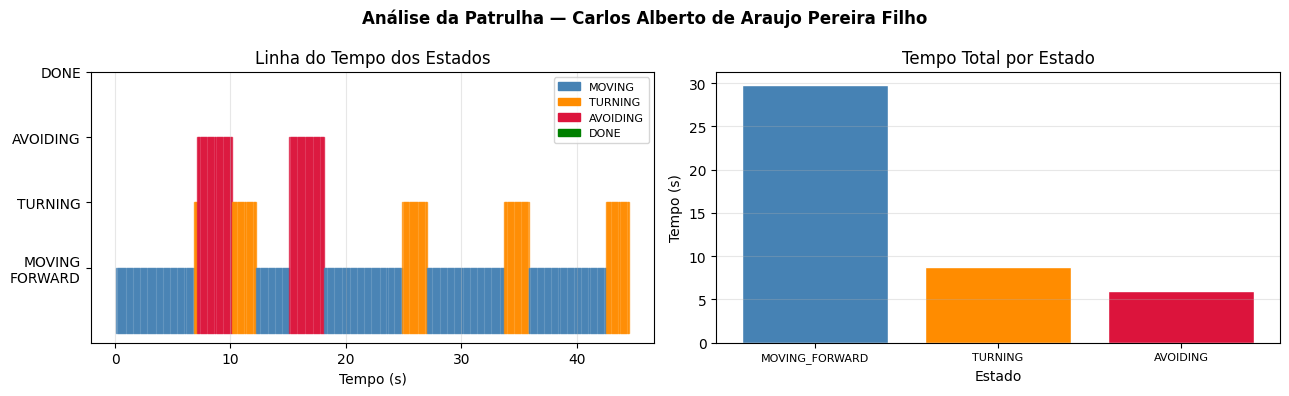


=== MÉTRICAS DA MISSÃO ===
Duração total:          44.5 s
Lados completos:        4/4
Paradas por obstáculo:  2
Tempo em movimento:     29.8 s (67%)
Tempo virando:          8.7 s (20%)
Tempo evitando:         6.0 s (13%)

📊 Gráfico salvo em resultados/analise_patrulha.png


In [5]:
# ═══════════════════════════════════════════════════════════
# ETAPA 4 — Analisar histórico da sessão e plotar métricas
# ═══════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

if not patrol.historico:
    print('🔴 Execute a Etapa 2 primeiro.')
else:
    tempos  = [h[0] for h in patrol.historico]
    estados = [h[1] for h in patrol.historico]

    # Mapear estados para números
    estado_map = {
        'MOVING_FORWARD': 1,
        'TURNING':        2,
        'AVOIDING':       3,
        'DONE':           4,
    }
    nums = [estado_map.get(e, 0) for e in estados]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    fig.suptitle(f'Análise da Patrulha — {ALUNO_NOME}',
                 fontsize=12, fontweight='bold')

    # Gráfico 1: Linha do tempo dos estados
    cores = {1: 'steelblue', 2: 'darkorange', 3: 'crimson', 4: 'green'}
    for i in range(len(tempos)-1):
        axes[0].fill_between([tempos[i], tempos[i+1]],
                              [0, 0], [nums[i], nums[i]],
                              color=cores.get(nums[i], 'gray'), alpha=0.7)
    axes[0].set(yticks=[1,2,3,4],
                yticklabels=['MOVING\nFORWARD','TURNING','AVOIDING','DONE'],
                xlabel='Tempo (s)', title='Linha do Tempo dos Estados')
    axes[0].grid(True, axis='x', alpha=0.3)

    # Legenda
    patches = [mpatches.Patch(color=c, label=n)
               for n, c in zip(['MOVING','TURNING','AVOIDING','DONE'],
                               ['steelblue','darkorange','crimson','green'])]
    axes[0].legend(handles=patches, loc='upper right', fontsize=8)

    # Gráfico 2: Distribuição de tempo por estado
    from collections import Counter
    contagem = Counter(estados)
    nomes = list(contagem.keys())
    vals  = list(contagem.values())
    cmap  = ['steelblue' if n=='MOVING_FORWARD' else
             'darkorange' if n=='TURNING' else
             'crimson' if n=='AVOIDING' else 'green' for n in nomes]
    axes[1].bar(nomes, [v/10 for v in vals], color=cmap, edgecolor='white')
    axes[1].set(xlabel='Estado', ylabel='Tempo (s)',
                title='Tempo Total por Estado')
    axes[1].tick_params(axis='x', labelsize=8)
    axes[1].grid(True, axis='y', alpha=0.3)

    plt.tight_layout()
    os.makedirs('resultados', exist_ok=True)
    plt.savefig('resultados/analise_patrulha.png', dpi=120)
    plt.show()

    # Métricas textuais
    print('\n=== MÉTRICAS DA MISSÃO ===')
    print(f'Duração total:          {max(tempos):.1f} s')
    print(f'Lados completos:        {patrol._lados}/4')
    print(f'Paradas por obstáculo:  {patrol.n_paradas}')
    t_mov = contagem.get('MOVING_FORWARD', 0) / 10
    t_tur = contagem.get('TURNING', 0) / 10
    t_avi = contagem.get('AVOIDING', 0) / 10
    print(f'Tempo em movimento:     {t_mov:.1f} s ({t_mov/max(tempos)*100:.0f}%)')
    print(f'Tempo virando:          {t_tur:.1f} s ({t_tur/max(tempos)*100:.0f}%)')
    print(f'Tempo evitando:         {t_avi:.1f} s ({t_avi/max(tempos)*100:.0f}%)')
    print('\n📊 Gráfico salvo em resultados/analise_patrulha.png')

---
## Etapa 5 — Commit Final (para nota)

In [ ]:
# ═══════════════════════════════════════════════════════════
# COMMIT FINAL — Execute após completar todas as etapas
# ═══════════════════════════════════════════════════════════
import subprocess, datetime

timestamp = datetime.datetime.now().strftime('%Y-%m-%d %H:%M')

cmds = [
    'git add .',
    f'git commit -m "feat(atividade): solução final PatrolNode [{timestamp}]"',
    'git push origin main'
]

for cmd in cmds:
    print(f'$ {cmd}')
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    saida = r.stdout or r.stderr
    if saida.strip():
        print(saida[:300])
    print()

print('='*55)
print('ENTREGA CONCLUÍDA!')
print(f'Aluno:  {ALUNO_NOME}')
print(f'Repo:   {REPO_URL}')
print(f'Data:   {timestamp}')
print('='*55)
print('\n📧 Envie o link do repositório no SUAP.')